# NYC building facades: what makes a facade unsafe?
Day 2 assignment, data cleaning + EDA

Amelia, Jerome, Kazuko, Sahil
AI Methods I, IAAC MaAI 2026/27

### Question
Which buildings end up with an **UNSAFE** facade inspection? We look at the result of the previous inspection,
the facade materials and wall types, the borough and the inspection cycle.

Data: NYC DOB NOW Facade Compliance Filings (87,483 filings). The clean table will be used in the supervised learning model.

# 0. Setup and data

## 0.1 Libraries

In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Folders (one level up from the notebook)
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Display options
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# Plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# One fixed color per facade status, used in every chart
STATUS_ORDER = ["SAFE", "SWARMP", "UNSAFE"]
STATUS_COLORS = {"SAFE": "#0ca30c", "SWARMP": "#fab219", "UNSAFE": "#d03b3b", "NO REPORT FILED": "#a3a29d"}

# Seed for anything random
RANDOM_STATE = 42

## 0.2 Getting the data
The dataset is public on NYC Open Data. If the CSV is not in `data/` yet, we download it from the city's website and save a copy,
so the data never has to be committed to GitHub.

In [3]:
# Load the raw data (download it first if it is not in data/ yet)
RAW_PATH = DATA_DIR / "facades_compliance_filings_2026-10-23.csv"
URL = "https://data.cityofnewyork.us/api/views/xubg-57si/rows.csv?accessType=DOWNLOAD"

if not RAW_PATH.exists():
    print("Downloading from NYC Open Data...")
    pd.read_csv(URL, low_memory=False).to_csv(RAW_PATH, index=False)

df = pd.read_csv(RAW_PATH, low_memory=False)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {RAW_PATH}")

Loaded 87,483 rows and 40 columns from ..\data\facades_compliance_filings_2026-10-23.csv


## 0.3 Dataset card

| | |
|---|---|
| Name | DOB NOW: Safety – Facades Compliance Filings |
| Source | NYC Open Data, [data.cityofnewyork.us/d/xubg-57si](https://data.cityofnewyork.us/d/xubg-57si) |
| Origin | Facade Inspection & Safety Program (FISP, Local Law 11): buildings taller than 6 stories must have their facade inspected every 5 years by a licensed inspector (QEWI) |
| One row | one filing = one inspection report for one building in one 5-year cycle |
| Size | 87,483 rows, 40 columns (downloaded 2026-10-23) |
| Licence | NYC Open Data, free public use |
| Limitations | only buildings over 6 stories, results are the inspector's judgement, no building age/height/size, many contact columns |

## 0.4 First look

In [4]:
# First 5 rows
df.head()

,TR6_NO,CONTROL_NO,FILING_TYPE,CYCLE,BIN,HOUSE_NO,STREET_NAME,BOROUGH,BLOCK,LOT,SEQUENCE_NO,SUBMITTED_ON,CURRENT_STATUS,QEWI_NAME,QEWI_BUS_NAME,QEWI_BUS_STREET_NAME,QEWI_CITY,QEWI_STATE,QEWI_ZIP,QEWI_NYS_LIC_NO,OWNER_NAME,OWNER_BUS_NAME,OWNER_BUS_STREET_NAME,OWNER_CITY,OWNER_ZIP,OWNER_STATE,FILING_DATE,FILING_STATUS,PRIOR_CYCLE_FILING_DATE,PRIOR_STATUS,FIELD_INSPECTION_COMPLETED_DATE,QEWI_SIGNED_DATE,LATE_FILING_AMT,FAILURE_TO_FILE_AMT,FAILURE_TO_CORRECT_AMT,COMMENTS,Exterior Wall Type(s),Exterior Wall Type Other Description,Exterior Wall Material(s),Exterior Wall Material Other Description
0,TR6-917501-9A-N1,917501,Auto-Generated,9.00,"1,090,530.00",147,EAST 86 STREET,Manhattan,1515,7505,NaN,NaN,No Report Filed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No Report Filed,NaN,NaN,NaN,NaN,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN
1,TR6-802744-8A-I1,802744,Initial,8.00,"1,019,150.00",148,EAST 39 STREET,Manhattan,894,52,1,04/09/2018,SWARMP,ALAN EPSTEIN,"EPSTEIN ENGINEERING, P.C.",1441 BROADWAY,NEW YORK,NY,10018,PE - 058291,MICHAEL FRANCISCO,"DRYDEN HOTEL ASSOCIATES, LLC",340 E 46TH STREET,NEW YORK,10017,NY,04/09/2018,SWARMP,02/21/2012,SWARMP,03/22/2018,09/27/2018,"3,500.00","1,000.00",0.00,NaN,BRICK MASONRY,NaN,MASONRY,NaN
2,TR6-709724-7A-I1,709724,Initial,7.00,"3,326,542.00",300,DUMONT AVENUE,Brooklyn,3576,1,7,12/03/2012,SAFE,HARENDRA V SEVAK,"GANDHI ENGINEERING, INC",111 JOHN STREET,NEW YORK,NY,NaN,NaN,NaN,NEW YORK CITY HOUSING AUTHORITY,90 CHURCH STREET,NEW YORK,NaN,NaN,12/03/2012,SAFE,02/16/2010,SAFE,10/25/2012,11/30/2012,0.00,0.00,0.00,DATA ENTERED BY RT,OTHER,CAVITY,OTHER,NaN
3,TR6-611824-NA-I1,611824,Initial,6.00,"4,436,310.00",8201,HAMMELS BOULEVARD,Queens,16114,2,4,10/16/2009,SAFE,SISIR BISWAS,"HAKS ENGINEERS, ARCHITECTS AND","40 WALL STREET, 11TH FLOOR",NEW YORK,NY,NaN,NaN,NaN,N.Y.C.H.A,90 CHURCH STREET,NEW YORK,NaN,NaN,10/16/2009,SAFE,03/25/2003,SAFE,03/11/2008,09/30/2009,0.00,0.00,0.00,CITY OWNED NYCHA,OTHER,CAVITY MASONRY,OTHER,NaN
4,TR6-904431-9A-S1,904431,Amended,9.00,"1,036,085.00",617,MADISON AVENUE,Manhattan,1294,46,1,11/30/2022,SAFE,VINCENT ORTIZ,CANY ARCHITECTURE & ENGINEERING DPC,134 W29TH STREET,NEW YORK,NY,10001,PE - 095247,GIANNA PILALIS,SL GREEN REALTY CORP,ONE VANDERBILT AVE,NEW YORK,10017,NY,11/30/2022,UNSAFE,02/21/2022,UNSAFE,11/21/2022,11/30/2022,"4,500.00","1,000.00","1,000.00",NaN,CURTAIN WALL; MASONRY CAVITY WALL; STEEL FRAME,NaN,GLASS; MASONRY; METAL,NaN


In [5]:
# Info: column names, types and non-missing counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87483 entries, 0 to 87482
Data columns (total 40 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   TR6_NO                                    87483 non-null  object 
 1   CONTROL_NO                                87483 non-null  int64  
 2   FILING_TYPE                               87483 non-null  object 
 3   CYCLE                                     87482 non-null  float64
 4   BIN                                       87456 non-null  float64
 5   HOUSE_NO                                  87483 non-null  object 
 6   STREET_NAME                               87483 non-null  object 
 7   BOROUGH                                   87483 non-null  object 
 8   BLOCK                                     87483 non-null  int64  
 9   LOT                                       87483 non-null  int64  
 10  SEQUENCE_NO                       

In [6]:
# Summary of all columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TR6_NO,87483,87458,TR6-815008-8B-N1,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CONTROL_NO,"87,483.00",NaN,NaN,NaN,"795,871.54","119,022.56","600,001.00","705,265.00","808,731.00","906,371.00","1,043,899.00"
FILING_TYPE,87483,4,Initial,54523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CYCLE,"87,482.00",NaN,NaN,NaN,7.88,1.18,6.00,7.00,8.00,9.00,10.00
BIN,"87,456.00",NaN,NaN,NaN,"1,947,307.79","1,222,003.80","1,000,000.00","1,035,462.00","1,082,677.50","3,116,170.00","5,863,301.00"
HOUSE_NO,87483,4475,1,555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET_NAME,87483,2735,BROADWAY,2484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BOROUGH,87483,5,Manhattan,50964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BLOCK,"87,483.00",NaN,NaN,NaN,"2,368.07","2,968.87",1.00,863.00,"1,506.00","2,835.00","99,999.00"
LOT,"87,483.00",NaN,NaN,NaN,"1,191.39","2,694.05",0.00,8.00,31.00,74.00,"9,100.00"


How to read this table:
- count: how many values are not missing (less than 87,483 = missing values)
- unique / top / freq: only for **text** columns. Number of different values, the most common one and how many times it shows up
- mean / std / min / max: only for **numbers**. Average, how spread out the values are, smallest and biggest
- 25% / 50% / 75%: half of the rows are between 25% and 75%, 50% is the median

Already some weird stuff here: `BLOCK` goes up to 99999, `BIN` and `CYCLE` are decimals, dates are text,
and penalties go up to almost $3 million. We fix this in the cleaning.

### Main columns

| Column | Meaning |
|---|---|
| `TR6_NO`, `CONTROL_NO` | filing number and control number |
| `FILING_TYPE` | initial, amended, subsequent, or auto-generated by the system |
| `CYCLE` | 5-year inspection cycle (6 to 10) |
| `BIN`, `BOROUGH`, `BLOCK`, `LOT`, `HOUSE_NO`, `STREET_NAME` | building ID and location |
| `FILING_STATUS` | **result of this filing: SAFE / SWARMP / UNSAFE / NO REPORT FILED (our target)** |
| `PRIOR_STATUS`, `PRIOR_CYCLE_FILING_DATE` | result and date of the previous cycle |
| `CURRENT_STATUS` | the building's status today (can change after this filing) |
| `FIELD_INSPECTION_COMPLETED_DATE`, `FILING_DATE`, `SUBMITTED_ON`, `QEWI_SIGNED_DATE` | dates |
| `LATE_FILING_AMT`, `FAILURE_TO_FILE_AMT`, `FAILURE_TO_CORRECT_AMT` | penalties in $ |
| `Exterior Wall Type(s)`, `Exterior Wall Material(s)` | facade construction and materials (can list several) |
| `QEWI_...`, `OWNER_...` | inspector and owner contact details |

SWARMP = **S**afe **W**ith **A** **R**epair and **M**aintenance **P**rogram: needs repairs, but not dangerous yet.

In [7]:
# Categories in the main columns
columns_to_check = ["FILING_TYPE", "FILING_STATUS", "PRIOR_STATUS", "BOROUGH", "CYCLE"]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- FILING_TYPE ---
FILING_TYPE
Initial           54523
Auto-Generated    19358
Amended            9383
Subsequent         4219
Name: count, dtype: int64

--- FILING_STATUS ---
FILING_STATUS
SAFE               28082
SWARMP             24472
No Report Filed    19811
UNSAFE             15118
Name: count, dtype: int64

--- PRIOR_STATUS ---
PRIOR_STATUS
NaN                26179
SWARMP             24036
SAFE               23858
UNSAFE             10555
No Report Filed     2855
Name: count, dtype: int64

--- BOROUGH ---
BOROUGH
Manhattan        50964
Brooklyn         12874
Bronx            11947
Queens           10907
Staten Island      791
Name: count, dtype: int64

--- CYCLE ---
CYCLE
9.00     30691
8.00     21941
6.00     15969
7.00     15682
10.00     3199
NaN          1
Name: count, dtype: int64


# 1. Data cleaning

In [8]:
# Make a clean copy of the original table
df_clean = df.copy()

We make a copy of `df` and do all the cleaning on `df_clean`, so the original data stays untouched.
This way we can compare before vs after at the end, and if we mess something up we can just start again from `df`.
(Without `.copy()` both names would point to the same table, so changing one would change the other too.)

## 1.1 Column names

In [9]:
# Make all column names UPPER_SNAKE_CASE
df_clean.columns = (
    df_clean.columns
    .str.replace("(s)", "S", regex=False)              # "Type(s)" -> "TypeS"
    .str.upper()                                       # all capital letters
    .str.replace(r"[^A-Z0-9]+", "_", regex=True)       # spaces and symbols -> "_"
    .str.strip("_")                                    # no "_" at the start or end
)

df_clean.columns.tolist()

['TR6_NO',
 'CONTROL_NO',
 'FILING_TYPE',
 'CYCLE',
 'BIN',
 'HOUSE_NO',
 'STREET_NAME',
 'BOROUGH',
 'BLOCK',
 'LOT',
 'SEQUENCE_NO',
 'SUBMITTED_ON',
 'CURRENT_STATUS',
 'QEWI_NAME',
 'QEWI_BUS_NAME',
 'QEWI_BUS_STREET_NAME',
 'QEWI_CITY',
 'QEWI_STATE',
 'QEWI_ZIP',
 'QEWI_NYS_LIC_NO',
 'OWNER_NAME',
 'OWNER_BUS_NAME',
 'OWNER_BUS_STREET_NAME',
 'OWNER_CITY',
 'OWNER_ZIP',
 'OWNER_STATE',
 'FILING_DATE',
 'FILING_STATUS',
 'PRIOR_CYCLE_FILING_DATE',
 'PRIOR_STATUS',
 'FIELD_INSPECTION_COMPLETED_DATE',
 'QEWI_SIGNED_DATE',
 'LATE_FILING_AMT',
 'FAILURE_TO_FILE_AMT',
 'FAILURE_TO_CORRECT_AMT',
 'COMMENTS',
 'EXTERIOR_WALL_TYPES',
 'EXTERIOR_WALL_TYPE_OTHER_DESCRIPTION',
 'EXTERIOR_WALL_MATERIALS',
 'EXTERIOR_WALL_MATERIAL_OTHER_DESCRIPTION']

36 columns were already written like `OWNER_CITY`, but 4 had spaces and brackets (like `Exterior Wall Type(s)`),
which are annoying to type and easy to get wrong. Now all of them follow the same style, e.g. `EXTERIOR_WALL_TYPES`.

## 1.2 Duplicates

In [10]:
# Check for duplicate rows and duplicate filing numbers
n_duplicates = df_clean.duplicated().sum()
n_duplicate_ids = df_clean["TR6_NO"].duplicated().sum()

print(f"Duplicate rows: {n_duplicates}")
print(f"Duplicate filing numbers: {n_duplicate_ids}")

Duplicate rows: 8
Duplicate filing numbers: 25


In [11]:
# Remove exact copies first, then look at filing numbers that are still repeated
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

repeated = df_clean[df_clean["TR6_NO"].duplicated(keep=False)].sort_values("TR6_NO")
print(f"Filing numbers still repeated: {df_clean['TR6_NO'].duplicated().sum()}")
repeated[["TR6_NO", "FILING_TYPE", "FILING_STATUS", "FILING_DATE", "CURRENT_STATUS"]].head(6)

Filing numbers still repeated: 17


,TR6_NO,FILING_TYPE,FILING_STATUS,FILING_DATE,CURRENT_STATUS
86215,TR6-601435-NA-I1,Initial,SAFE,02/01/2007,SAFE
35096,TR6-601435-NA-I1,Initial,SAFE,02/01/2007,SWARMP
57163,TR6-601435-NA-N1,Auto-Generated,No Report Filed,NaN,SAFE
35813,TR6-601435-NA-N1,Auto-Generated,No Report Filed,NaN,SWARMP
86811,TR6-610070-NA-I1,Initial,SWARMP,10/11/2007,SWARMP
71679,TR6-610070-NA-I1,Initial,SWARMP,10/11/2007,SWARMP


`duplicated()` gives True for every row that is an exact copy of a row above, `.sum()` counts them. We also check `TR6_NO` alone,
in case the same filing shows up twice with different values.

In [12]:
# Keep one row per filing number
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset="TR6_NO", keep="first").reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean)} repeated filings, {len(df_clean):,} left")

Removed 17 repeated filings, 87,458 left


8 rows were exact copies. Some filing numbers were still repeated with only `CURRENT_STATUS` different
(the building's status today, which we drop anyway in 1.4). We can't tell which one is right, so we keep the first one.
It's a tiny number of rows.

## 1.3 Missing values

In [13]:
# Number and percentage of missing values per column
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing
    })
    return report.sort_values("pct_missing", ascending=False)

missing = missing_report(df_clean)
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
EXTERIOR_WALL_MATERIAL_OTHER_DESCRIPTION,83529,95.51
EXTERIOR_WALL_TYPE_OTHER_DESCRIPTION,64614,73.88
COMMENTS,63673,72.80
QEWI_NYS_LIC_NO,51276,58.63
OWNER_ZIP,51233,58.58
OWNER_STATE,51230,58.58
QEWI_ZIP,51212,58.56
OWNER_NAME,51205,58.55
PRIOR_CYCLE_FILING_DATE,28817,32.95
PRIOR_STATUS,26165,29.92


We made a small function so we can reuse it later. It counts the missing values (NaN) in every column and turns them into a % of all rows,
sorted from most to least missing. We only show the columns that actually have missing values.

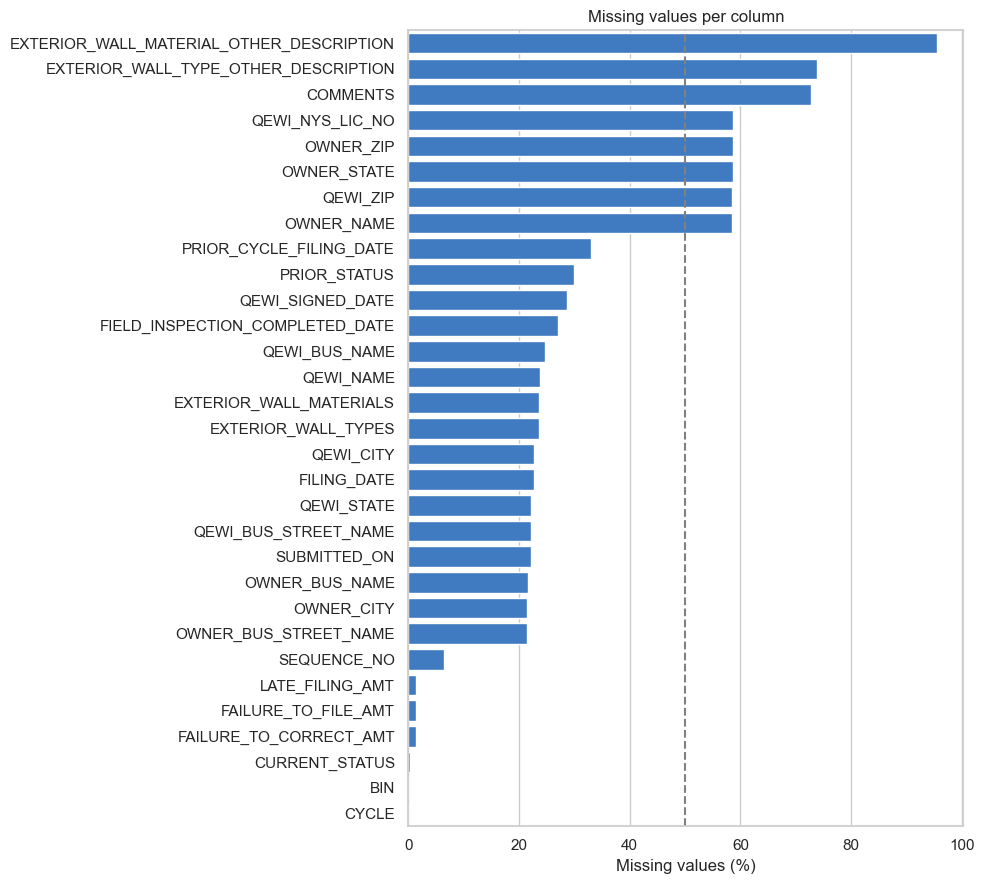

In [14]:
# Bar chart of the columns with missing values
missing_to_plot = missing[missing["pct_missing"] > 0]

fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="#2a78d6", ax=ax)
ax.axvline(50, color="grey", linestyle="--")
ax.set_title("Missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

- the two "Other Description" columns and `COMMENTS` are almost empty (73-96%)
- owner name, zip and state and the inspector's zip and license number are missing for ~59%
- ~22% of rows are missing all the report details (dates, inspector, wall type...). We look at those in 1.5
- the location (`BOROUGH`, `BLOCK`, `LOT`) and the target `FILING_STATUS` are complete

## 1.4 Dropping columns

| Column | Why |
|---|---|
| `COMMENTS`, `EXTERIOR_WALL_TYPE_OTHER_DESCRIPTION`, `EXTERIOR_WALL_MATERIAL_OTHER_DESCRIPTION` | (almost) empty free text |
| `QEWI_NAME`, `QEWI_BUS_NAME`, `QEWI_BUS_STREET_NAME`, `QEWI_CITY`, `QEWI_STATE`, `QEWI_ZIP`, `QEWI_NYS_LIC_NO` | inspector contact details, about the person not the facade |
| `OWNER_NAME`, `OWNER_BUS_NAME`, `OWNER_BUS_STREET_NAME`, `OWNER_CITY`, `OWNER_STATE`, `OWNER_ZIP` | owner contact details, same reason |
| `CONTROL_NO` | another ID, we keep `TR6_NO` |
| `SUBMITTED_ON` | the same as `FILING_DATE` in 92% of filings (checked below) |
| `CURRENT_STATUS` | the status *today*, can be updated after this filing, so it would give away the answer (leakage) |

In [15]:
# Check: how often is SUBMITTED_ON the same as FILING_DATE?
both = df_clean[["SUBMITTED_ON", "FILING_DATE"]].dropna()
print(f"SUBMITTED_ON == FILING_DATE: {(both['SUBMITTED_ON'] == both['FILING_DATE']).mean() * 100:.1f}% of rows")

SUBMITTED_ON == FILING_DATE: 92.4% of rows


In [16]:
# Column removal
columns_to_drop = [
    "COMMENTS",
    "EXTERIOR_WALL_TYPE_OTHER_DESCRIPTION",
    "EXTERIOR_WALL_MATERIAL_OTHER_DESCRIPTION",
    "QEWI_NAME", "QEWI_BUS_NAME", "QEWI_BUS_STREET_NAME", "QEWI_CITY", "QEWI_STATE", "QEWI_ZIP", "QEWI_NYS_LIC_NO",
    "OWNER_NAME", "OWNER_BUS_NAME", "OWNER_BUS_STREET_NAME", "OWNER_CITY", "OWNER_STATE", "OWNER_ZIP",
    "CONTROL_NO",
    "SUBMITTED_ON",
    "CURRENT_STATUS",
]

df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Remaining columns ({df_clean.shape[1]}): {df_clean.columns.tolist()}")

Remaining columns (21): ['TR6_NO', 'FILING_TYPE', 'CYCLE', 'BIN', 'HOUSE_NO', 'STREET_NAME', 'BOROUGH', 'BLOCK', 'LOT', 'SEQUENCE_NO', 'FILING_DATE', 'FILING_STATUS', 'PRIOR_CYCLE_FILING_DATE', 'PRIOR_STATUS', 'FIELD_INSPECTION_COMPLETED_DATE', 'QEWI_SIGNED_DATE', 'LATE_FILING_AMT', 'FAILURE_TO_FILE_AMT', 'FAILURE_TO_CORRECT_AMT', 'EXTERIOR_WALL_TYPES', 'EXTERIOR_WALL_MATERIALS']


`drop(columns=...)` removes the columns in the list. We only keep what helps with our question;
the rest was empty, about people instead of the facade, a copy of another column, or leakage.

## 1.5 Filings that are not real inspections

In [17]:
# Filing type vs filing status
pd.crosstab(df_clean["FILING_TYPE"], df_clean["FILING_STATUS"])

FILING_STATUS,No Report Filed,SAFE,SWARMP,UNSAFE
FILING_TYPE,,,,
Amended,0,6993,2388,1
Auto-Generated,19347,0,0,0
Initial,452,19880,21630,12552
Subsequent,0,1207,449,2559


In [18]:
# Do the NO REPORT FILED rows have any report details?
# (.str.upper() because the capitals are only fixed in 1.6: here it is still "No Report Filed")
no_report = df_clean["FILING_STATUS"].str.upper() == "NO REPORT FILED"
detail_columns = ["FILING_DATE", "FIELD_INSPECTION_COMPLETED_DATE", "EXTERIOR_WALL_MATERIALS"]
print("Share of NO REPORT FILED rows with a value:")
print(df_clean.loc[no_report, detail_columns].notna().mean().round(3))
print()
print("Share of NO REPORT FILED per cycle (%):")
print((pd.crosstab(df_clean["CYCLE"], no_report, normalize="index")[True] * 100).round(1))

Share of NO REPORT FILED rows with a value:
FILING_DATE                       0.00
FIELD_INSPECTION_COMPLETED_DATE   0.02
EXTERIOR_WALL_MATERIALS           0.07
dtype: float64

Share of NO REPORT FILED per cycle (%):
CYCLE
6.00     4.20
7.00     6.30
8.00    28.70
9.00    38.50
10.00    0.30
Name: True, dtype: float64


Every **AUTO-GENERATED** filing is a `NO REPORT FILED` placeholder: the system creates it when the owner doesn't file on time.
These rows have no inspection, no dates and no wall information, so there is nothing to learn about the facade from them.
That's also why cycles 8 and 9 have so many of them.

Our question is about the facade condition, so we keep only real reports (SAFE / SWARMP / UNSAFE).
`NO REPORT FILED` is still used as a value of `PRIOR_STATUS` (the previous cycle had no report).

In [19]:
# Keep only real inspection reports
rows_before = len(df_clean)
df_clean = df_clean[~no_report].reset_index(drop=True)

print(f"Removed {rows_before - len(df_clean):,} filings without a report, {len(df_clean):,} left")
print(df_clean["FILING_TYPE"].value_counts())

Removed 19,799 filings without a report, 67,659 left
FILING_TYPE
Initial       54062
Amended        9382
Subsequent     4215
Name: count, dtype: int64


## 1.6 Categories written in different ways

In [20]:
# Borough and status: same thing written in different capitals?
print(df_clean["BOROUGH"].value_counts())
print()
print(df_clean["PRIOR_STATUS"].value_counts(dropna=False))

BOROUGH
Manhattan        40640
Brooklyn          9333
Bronx             8723
Queens            8364
Staten Island      599
Name: count, dtype: int64

PRIOR_STATUS
SWARMP             23612
SAFE               23344
UNSAFE             10444
NaN                 7997
No Report Filed     2262
Name: count, dtype: int64


In [21]:
# Example: the same city written in different ways
city_examples = df["QEWI_CITY"].dropna()
city_examples[city_examples.str.upper() == "BROOKLYN"].value_counts()

QEWI_CITY
BROOKLYN    2354
Brooklyn       7
Name: count, dtype: int64

Same values are written in different ways: `Manhattan` here but uppercase everywhere else, `No Report Filed` next to `SAFE`,
`Brooklyn`/`BROOKLYN`, `1st Avenue`/`1ST AVENUE`, and double spaces like `149TH  STREET`.
Most values are already in capitals, so we put **all text** in capitals, with single spaces.

In [22]:
# All text in capitals, one space between words, no spaces at the ends
text_columns = df_clean.select_dtypes(include=["object", "string"]).columns
before = df_clean[text_columns].nunique()

for col in text_columns:
    df_clean[col] = (
        df_clean[col]
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

# How many different spellings were merged in each column
merged = (before - df_clean[text_columns].nunique()).sort_values(ascending=False)
merged[merged > 0].to_frame("spellings merged")

,spellings merged
STREET_NAME,262


In [23]:
# Check again
print(df_clean["BOROUGH"].value_counts())
print()
print(df_clean["PRIOR_STATUS"].value_counts(dropna=False))

BOROUGH
MANHATTAN        40640
BROOKLYN          9333
BRONX             8723
QUEENS            8364
STATEN ISLAND      599
Name: count, dtype: int64

PRIOR_STATUS
SWARMP             23612
SAFE               23344
UNSAFE             10444
NaN                 7997
NO REPORT FILED     2262
Name: count, dtype: int64


## 1.7 Wrong types and values that can't be right

In [24]:
# Dates are text (MM/DD/YYYY) -> real dates
date_columns = ["FILING_DATE", "PRIOR_CYCLE_FILING_DATE", "FIELD_INSPECTION_COMPLETED_DATE", "QEWI_SIGNED_DATE"]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], format="%m/%d/%Y", errors="coerce")

# Dates after the download date can't be right
download_date = pd.Timestamp("2026-10-23")
for col in date_columns:
    future = df_clean[col] > download_date
    print(f"{col}: {future.sum()} future dates")
    df_clean.loc[future, col] = pd.NaT

df_clean[date_columns].agg(["min", "max"]).T

FILING_DATE: 0 future dates
PRIOR_CYCLE_FILING_DATE: 0 future dates
FIELD_INSPECTION_COMPLETED_DATE: 0 future dates
QEWI_SIGNED_DATE: 1 future dates


,min,max
FILING_DATE,2001-11-02,2026-10-21
PRIOR_CYCLE_FILING_DATE,1992-02-18,2026-09-11
FIELD_INSPECTION_COMPLETED_DATE,1997-07-23,2026-10-20
QEWI_SIGNED_DATE,1997-02-07,2026-10-21


`errors="coerce"` turns anything that is not a valid date into NaT (missing date). One inspector signature was dated in the future, so we set it to missing.

In [25]:
# Whole numbers stored as decimals or text
df_clean["CYCLE"] = df_clean["CYCLE"].astype("Int64")

# SEQUENCE_NO: typos like "O4" (letter O) and "0.7"
print("Values that are not whole numbers:",
      df_clean.loc[~df_clean["SEQUENCE_NO"].fillna("1").str.fullmatch(r"\d+"), "SEQUENCE_NO"].unique())
sequence = pd.to_numeric(df_clean["SEQUENCE_NO"].str.replace("O", "0"), errors="coerce")
sequence[sequence % 1 != 0] = np.nan
df_clean["SEQUENCE_NO"] = sequence.astype("Int64")

Values that are not whole numbers: ['0.7' 'O4']


`Int64` (capital I) is the pandas whole-number type that also allows missing values.
`O4` was typed with the letter O instead of a zero, so we fix it; `0.7` can't be a sequence number, so it becomes missing.

In [26]:
# Building IDs (BIN) and blocks
# A BIN starts with the borough number: 1 Manhattan, 2 Bronx, 3 Brooklyn, 4 Queens, 5 Staten Island
# and BINs like 1000000 are placeholders for "no BIN"
borough_number = {"MANHATTAN": "1", "BRONX": "2", "BROOKLYN": "3", "QUEENS": "4", "STATEN ISLAND": "5"}
bin_text = df_clean["BIN"].astype("Int64").astype("string")

placeholder_bin = bin_text.str.fullmatch(r"\d000000", na=False)
wrong_borough = bin_text.notna() & (bin_text.str[0] != df_clean["BOROUGH"].map(borough_number))
block_99999 = df_clean["BLOCK"] == 99999

print(f"Placeholder BINs: {placeholder_bin.sum()}")
print(f"BIN in the wrong borough: {wrong_borough.sum()}")
print(f"BLOCK = 99999: {block_99999.sum()}")

Placeholder BINs: 3
BIN in the wrong borough: 9
BLOCK = 99999: 18


In [27]:
# Impossible values -> NaN
df_clean["BIN"] = df_clean["BIN"].astype("Int64")
df_clean.loc[placeholder_bin | wrong_borough, "BIN"] = pd.NA
df_clean["BLOCK"] = df_clean["BLOCK"].replace(99999, np.nan).astype("Int64")

print(f"Missing BIN now: {df_clean['BIN'].isna().sum()}")

Missing BIN now: 12


BINs like `1000000` are placeholders the city uses when a building has no number yet, and a few BINs point to a different borough than the address.
Block 99999 is not a real block. We can't know the right values, so we set them to NaN instead of deleting the rows.

## 1.8 New columns
- `IS_UNSAFE`: 1 if the filing is UNSAFE, 0 otherwise (a simple version of the target)
- `FILING_YEAR`: year of the filing
- `DAYS_INSPECTION_TO_FILING`: days between the inspection and the filing
- `TOTAL_PENALTY_AMT`: all penalties added up
- `HAS_PRIOR_CYCLE`: 1 if the building had a previous cycle
- `WALL_TYPE_...` / `MATERIAL_...`: 1/0 columns for the 8 most common wall types and materials

In [28]:
# Target as 1/0
df_clean["IS_UNSAFE"] = (df_clean["FILING_STATUS"] == "UNSAFE").astype(int)

# Year and delay
df_clean["FILING_YEAR"] = df_clean["FILING_DATE"].dt.year.astype("Int64")
df_clean["DAYS_INSPECTION_TO_FILING"] = (df_clean["FILING_DATE"] - df_clean["FIELD_INSPECTION_COMPLETED_DATE"]).dt.days

# All penalties (min_count=1: stays NaN if all three are missing)
penalty_columns = ["LATE_FILING_AMT", "FAILURE_TO_FILE_AMT", "FAILURE_TO_CORRECT_AMT"]
df_clean["TOTAL_PENALTY_AMT"] = df_clean[penalty_columns].sum(axis=1, min_count=1)

# Previous cycle or not
df_clean["HAS_PRIOR_CYCLE"] = df_clean["PRIOR_STATUS"].notna().astype(int)

new_columns = ["IS_UNSAFE", "FILING_YEAR", "DAYS_INSPECTION_TO_FILING", "TOTAL_PENALTY_AMT", "HAS_PRIOR_CYCLE"]
df_clean[new_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
IS_UNSAFE,"67,659.00",0.22,0.42,0.00,0.00,0.00,0.00,1.00
FILING_YEAR,"67,653.00","2,016.34",6.17,"2,001.00","2,012.00","2,017.00","2,022.00","2,026.00"
DAYS_INSPECTION_TO_FILING,"63,352.00",56.11,182.33,"-3,953.00",8.00,22.00,48.00,"4,949.00"
TOTAL_PENALTY_AMT,"67,533.00","29,861.85","83,395.77",0.00,0.00,"7,000.00","30,050.00","2,981,050.00"
HAS_PRIOR_CYCLE,"67,659.00",0.88,0.32,0.00,1.00,1.00,1.00,1.00


In [29]:
# Wall types and materials can list several values: "MASONRY; TERRA COTTA"
# -> one 1/0 column for each of the 8 most common values
for col, prefix in [("EXTERIOR_WALL_TYPES", "WALL_TYPE"), ("EXTERIOR_WALL_MATERIALS", "MATERIAL")]:
    dummies = df_clean[col].str.get_dummies(sep="; ")
    top = dummies.sum().sort_values(ascending=False).head(8).index
    dummies = dummies[top].add_prefix(prefix + "_")
    dummies.columns = dummies.columns.str.replace(r"[^A-Z0-9]+", "_", regex=True)
    dummies[df_clean[col].isna()] = pd.NA            # no wall info -> missing, not 0
    df_clean = df_clean.join(dummies.astype("Int64"))
    print(f"{prefix}: {dummies.columns.tolist()}")

WALL_TYPE: ['WALL_TYPE_BRICK_MASONRY', 'WALL_TYPE_OTHER', 'WALL_TYPE_MASONRY_LOAD_BEARING_WALL', 'WALL_TYPE_TERRA_COTTA', 'WALL_TYPE_MASONRY_CAVITY_WALL', 'WALL_TYPE_STEEL_FRAME', 'WALL_TYPE_CONCRETE', 'WALL_TYPE_CONCRETE_FRAME']
MATERIAL: ['MATERIAL_MASONRY', 'MATERIAL_OTHER', 'MATERIAL_TERRA_COTTA', 'MATERIAL_NATURAL_STONE', 'MATERIAL_CONCRETE', 'MATERIAL_STUCCO_EIFS', 'MATERIAL_GLASS', 'MATERIAL_METAL']


In [30]:
# Negative delays: filed before the inspection happened
negative = df_clean["DAYS_INSPECTION_TO_FILING"] < 0
print(f"Filings dated before their inspection: {negative.sum():,}")
df_clean.loc[negative, "DAYS_INSPECTION_TO_FILING"] = np.nan

Filings dated before their inspection: 3,989


`str.get_dummies` splits each cell on `"; "` and makes one column per value, with 1 if the facade has it. A model can't use
`"MASONRY; TERRA COTTA"` as text, but it can use `MATERIAL_MASONRY = 1` and `MATERIAL_TERRA_COTTA = 1`.
Some filings are dated before their own inspection, which can't be right, so that delay is set to missing.

## 1.9 Outliers

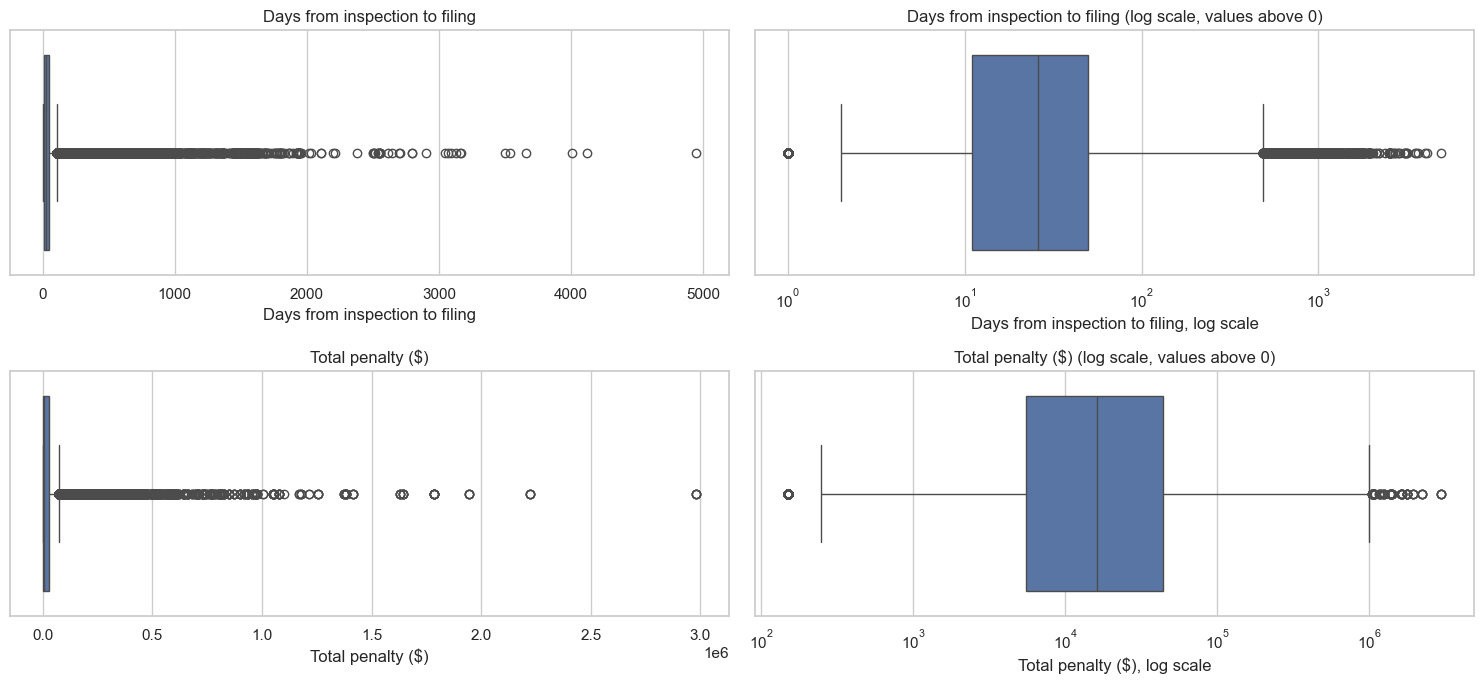

In [31]:
# Boxplots of the delay and the penalties, normal scale and log scale
fig, axes = plt.subplots(2, 2, figsize=(15, 7))

for row, (col, label) in enumerate([
    ("DAYS_INSPECTION_TO_FILING", "Days from inspection to filing"),
    ("TOTAL_PENALTY_AMT", "Total penalty ($)"),
]):
    values = df_clean[col].dropna()
    sns.boxplot(x=values, ax=axes[row, 0])
    axes[row, 0].set_title(label)
    axes[row, 0].set_xlabel(label)

    sns.boxplot(x=values[values > 0], log_scale=True, ax=axes[row, 1])
    axes[row, 1].set_title(f"{label} (log scale, values above 0)")
    axes[row, 1].set_xlabel(f"{label}, log scale")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# IQR rule and percentile rule
for col in ["DAYS_INSPECTION_TO_FILING", "TOTAL_PENALTY_AMT"]:
    values = df_clean[col]

    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_outliers = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

    p01, p99 = values.quantile([0.01, 0.99])
    pct_outliers = (values < p01) | (values > p99)

    print(col)
    print(f"  IQR rule: {iqr_outliers.sum():,} rows (above {q3 + 1.5 * iqr:,.0f})")
    print(f"  Percentile rule: {pct_outliers.sum():,} rows (below {p01:,.0f} or above {p99:,.0f})")

DAYS_INSPECTION_TO_FILING
  IQR rule: 6,524 rows (above 108)
  Percentile rule: 594 rows (below 0 or above 914)
TOTAL_PENALTY_AMT
  IQR rule: 6,189 rows (above 75,125)
  Percentile rule: 674 rows (below 0 or above 332,130)


In [33]:
# Which filings have the longest delays and the biggest penalties?
columns_to_show = ["TR6_NO", "CYCLE", "FILING_STATUS", "FIELD_INSPECTION_COMPLETED_DATE", "FILING_DATE",
                   "DAYS_INSPECTION_TO_FILING", "TOTAL_PENALTY_AMT"]
print(df_clean.nlargest(5, "DAYS_INSPECTION_TO_FILING")[columns_to_show])
print()
print(df_clean.nlargest(5, "TOTAL_PENALTY_AMT")[columns_to_show])
print()
print("UNSAFE share among the top 1% penalties:",
      f"{df_clean.loc[df_clean['TOTAL_PENALTY_AMT'] > df_clean['TOTAL_PENALTY_AMT'].quantile(0.99), 'IS_UNSAFE'].mean() * 100:.0f}%")

                 TR6_NO  CYCLE FILING_STATUS FIELD_INSPECTION_COMPLETED_DATE  \
7061   TR6-907154-9B-I2   <NA>          SAFE                      2011-11-10   
26185  TR6-904506-9A-I2      9          SAFE                      2012-01-20   
23016  TR6-709160-7C-A1      7          SAFE                      2007-02-13   
20472  TR6-606452-NA-I1      6          SAFE                      2000-02-08   
12591  TR6-602022-NA-I1      6        SWARMP                      2000-02-15   

      FILING_DATE  DAYS_INSPECTION_TO_FILING  TOTAL_PENALTY_AMT  
7061   2025-05-29                   4,949.00          38,000.00  
26185  2023-05-01                   4,119.00         182,900.00  
23016  2018-01-30                   4,004.00          21,250.00  
20472  2010-02-17                   3,662.00           6,500.00  
12591  2009-10-22                   3,537.00          19,250.00  

                 TR6_NO  CYCLE FILING_STATUS FIELD_INSPECTION_COMPLETED_DATE  \
3196   TR6-708865-7A-I1      7        UNSA

Same two rules as in class (IQR and 1%-99%).

- **Delay:** the IQR rule flags 6,524 filings (more than 108 days), the 1%-99% rule 594 (more than 914 days, ~2.5 years).
  The longest ones say the inspection was 10+ years before the filing, which probably means an old inspection date was copied into a new report.
  We can't check that, so we keep them and use the median when we talk about delays.
- **Penalties:** the IQR rule flags 6,189 filings (more than $75,125), the 1%-99% rule 674 (more than $332,130).
  The top 4 are the same building fined $2,981,050 in every cycle, and 58% of the top 1% are UNSAFE: these are real fines for buildings
  that don't fix their facade, not mistakes. We keep them. (Penalties come *after* the result, so they won't be model inputs anyway.)

## 1.10 Remaining missing values

In [34]:
# Missing values after cleaning
missing_report(df_clean).head(8)

,n_missing,pct_missing
PRIOR_CYCLE_FILING_DATE,10087,14.91
DAYS_INSPECTION_TO_FILING,8296,12.26
PRIOR_STATUS,7997,11.82
QEWI_SIGNED_DATE,5379,7.95
FIELD_INSPECTION_COMPLETED_DATE,4302,6.36
SEQUENCE_NO,2781,4.11
MATERIAL_METAL,2114,3.12
MATERIAL_OTHER,2114,3.12


In [35]:
# Is the missing wall information random? % missing per cycle
df_clean.groupby("CYCLE")["EXTERIOR_WALL_MATERIALS"].apply(lambda s: s.isna().mean() * 100).round(1)

CYCLE
6    3.50
7    7.00
8    3.50
9    0.00
10   0.00
Name: EXTERIOR_WALL_MATERIALS, dtype: float64

After cleaning, most missing values are about history: 12% of filings have no `PRIOR_STATUS` because it's the building's first cycle in the data.
That is information, not an error, so in the EDA we show it as its own group (`NO PRIOR CYCLE`) instead of filling it.
The delay is missing for 12% (missing dates + the negative delays we removed).
Wall information is missing for only ~3%, and not at random: 7% in cycle 7, 0% in cycles 9 and 10. Filling it with the most common material
would be making up facades, so we leave it as NaN.

## 1.11 Final check and save

In [36]:
# Final columns
wall_columns = [c for c in df_clean.columns if c.startswith("WALL_TYPE_")]
material_columns = [c for c in df_clean.columns if c.startswith("MATERIAL_")]

final_columns = [
    # id and location
    "TR6_NO", "BIN", "BOROUGH", "BLOCK", "LOT", "HOUSE_NO", "STREET_NAME",
    # filing
    "FILING_TYPE", "CYCLE", "SEQUENCE_NO", "FILING_YEAR",
    # target
    "FILING_STATUS", "IS_UNSAFE",
    # history
    "PRIOR_STATUS", "HAS_PRIOR_CYCLE",
    # facade
    "EXTERIOR_WALL_TYPES", "EXTERIOR_WALL_MATERIALS", *wall_columns, *material_columns,
    # dates and delay
    "FIELD_INSPECTION_COMPLETED_DATE", "FILING_DATE", "PRIOR_CYCLE_FILING_DATE", "QEWI_SIGNED_DATE",
    "DAYS_INSPECTION_TO_FILING",
    # penalties (leakage if we model: they come after the result)
    *penalty_columns, "TOTAL_PENALTY_AMT",
]

df_clean = df_clean[final_columns]
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67659 entries, 0 to 67658
Data columns (total 42 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   TR6_NO                               67659 non-null  object        
 1   BIN                                  67647 non-null  Int64         
 2   BOROUGH                              67659 non-null  object        
 3   BLOCK                                67641 non-null  Int64         
 4   LOT                                  67659 non-null  int64         
 5   HOUSE_NO                             67659 non-null  object        
 6   STREET_NAME                          67659 non-null  object        
 7   FILING_TYPE                          67659 non-null  object        
 8   CYCLE                                67658 non-null  Int64         
 9   SEQUENCE_NO                          64878 non-null  Int64         
 10  FILING_YEA

We pick the columns based on our question: the result (`FILING_STATUS`, `IS_UNSAFE`) and the things we think affect it
(previous result, facade, location, cycle). Penalties are kept for the EDA but marked as leakage, because the city gives them *after* the result.

In [37]:
# Comparing the raw and the clean table
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing"],
)
comparison

,raw,clean
rows,"87,483.00","67,659.00"
columns,40.00,42.00
numeric columns,8.00,29.00
average % missing,23.42,2.73


In [38]:
# Save the cleaned table in data/processed/
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

clean_path = PROCESSED_DIR / "facades_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Cleaned table saved to {clean_path} ({clean_path.stat().st_size / 1e6:.2f} MB)")

Cleaned table saved to ..\data\processed\facades_clean.csv (15.55 MB)


# 2. EDA

**EDA** = looking at the data from every angle (stats + plots) to understand it before building any model.
We use it to answer our question and to see which variables actually matter.

Main variable: `FILING_STATUS` (SAFE / SWARMP / UNSAFE) and its simple version `IS_UNSAFE`.

## 2.1 Basic stats

In [39]:
# Target balance
status_counts = df_clean["FILING_STATUS"].value_counts().reindex(STATUS_ORDER)
pd.DataFrame({"count": status_counts, "%": status_counts / status_counts.sum() * 100})

,count,%
FILING_STATUS,,
SAFE,28080,41.50
SWARMP,24467,36.16
UNSAFE,15112,22.34


In [40]:
# Main numeric columns
eda_columns = ["DAYS_INSPECTION_TO_FILING", "TOTAL_PENALTY_AMT", "FILING_YEAR", "CYCLE", "SEQUENCE_NO"]

stats = df_clean[eda_columns].astype(float).describe().T
stats["skewness"] = df_clean[eda_columns].astype(float).skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
DAYS_INSPECTION_TO_FILING,"59,363.00",67.90,177.31,0.00,10.00,25.00,49.00,"4,949.00",7.42
TOTAL_PENALTY_AMT,"67,533.00","29,861.85","83,395.77",0.00,0.00,"7,000.00","30,050.00","2,981,050.00",11.54
FILING_YEAR,"67,653.00","2,016.34",6.17,"2,001.00","2,012.00","2,017.00","2,022.00","2,026.00",-0.15
CYCLE,"67,658.00",7.70,1.23,6.00,7.00,8.00,9.00,10.00,-0.01
SEQUENCE_NO,"64,878.00",1.99,3.51,0.00,1.00,1.00,1.00,53.00,6.68


Skewness: 0 means symmetric, above 1 means a few very big values pull everything to the right. Delay (7.4) and penalties (11.5) are really skewed,
that's why we look at medians and log scales.

- after removing the filings without a report: SAFE 41.5%, SWARMP 36.2%, UNSAFE 22.3%. UNSAFE is the smallest class, about 1 in 5
- median delay 25 days, mean 68: a few very late filings pull the mean up, so we use the median
- median penalty $7,000, mean $29,862, same reason
- almost all filings have sequence number 1 (the first report for that building in that cycle)

## 2.2 Distributions

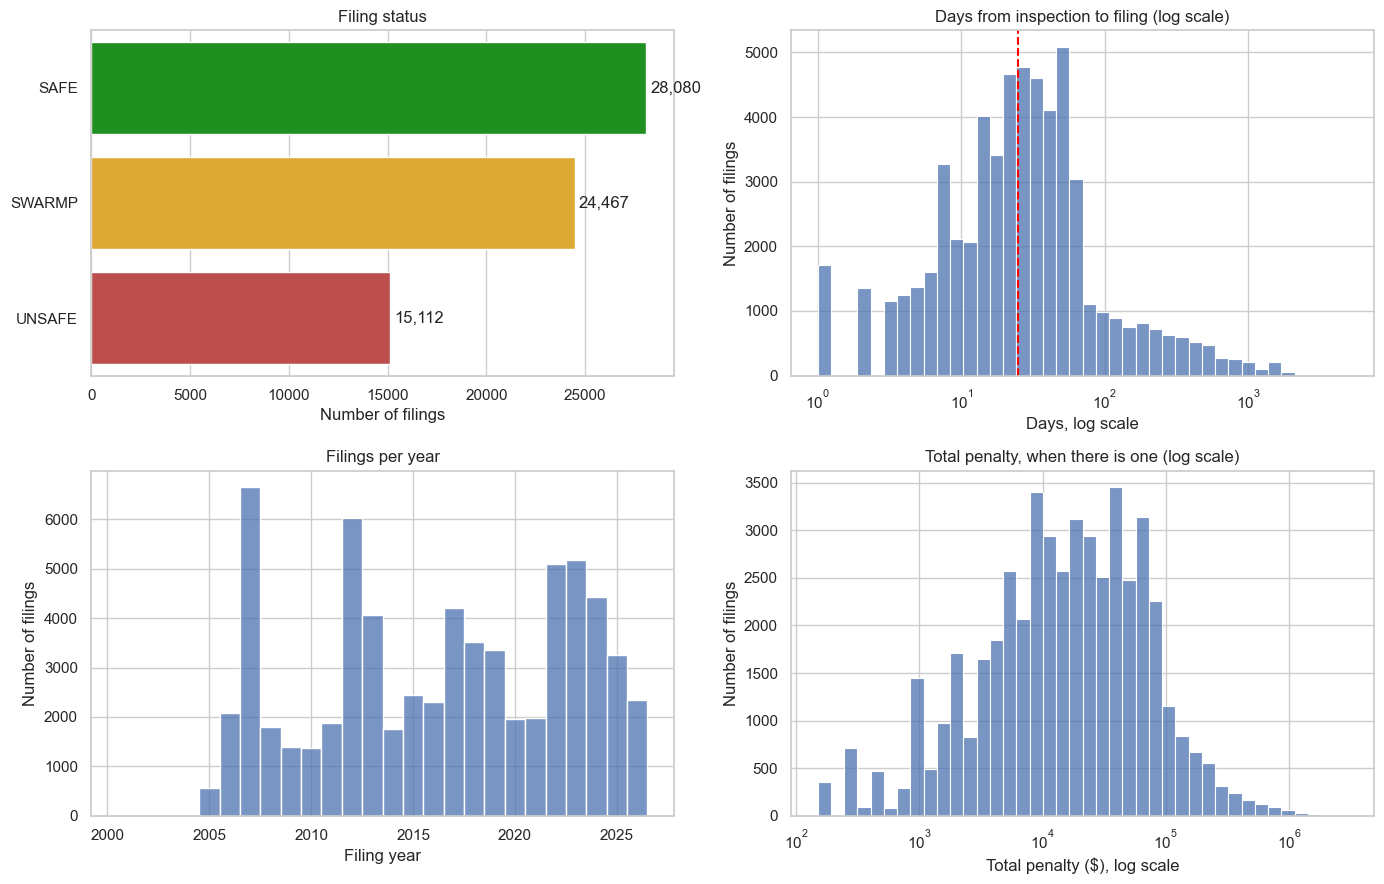

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Target
sns.countplot(data=df_clean, y="FILING_STATUS", order=STATUS_ORDER, hue="FILING_STATUS",
              palette=STATUS_COLORS, legend=False, ax=axes[0, 0])
axes[0, 0].bar_label(axes[0, 0].containers[0], fmt="{:,.0f}", padding=3)
for container in axes[0, 0].containers[1:]:
    axes[0, 0].bar_label(container, fmt="{:,.0f}", padding=3)
axes[0, 0].set_title("Filing status")
axes[0, 0].set_xlabel("Number of filings")
axes[0, 0].set_ylabel("")

# Delay
delay = df_clean["DAYS_INSPECTION_TO_FILING"]
sns.histplot(delay[delay > 0], bins=40, log_scale=True, ax=axes[0, 1])
axes[0, 1].axvline(delay.median(), color="red", linestyle="--")
axes[0, 1].set_title("Days from inspection to filing (log scale)")
axes[0, 1].set_xlabel("Days, log scale")
axes[0, 1].set_ylabel("Number of filings")

# Filings per year
sns.histplot(df_clean["FILING_YEAR"].dropna().astype(int), discrete=True, ax=axes[1, 0])
axes[1, 0].set_title("Filings per year")
axes[1, 0].set_xlabel("Filing year")
axes[1, 0].set_ylabel("Number of filings")

# Penalties
penalty = df_clean["TOTAL_PENALTY_AMT"]
sns.histplot(penalty[penalty > 0], bins=40, log_scale=True, ax=axes[1, 1])
axes[1, 1].set_title("Total penalty, when there is one (log scale)")
axes[1, 1].set_xlabel("Total penalty ($), log scale")
axes[1, 1].set_ylabel("Number of filings")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [42]:
# Share of filings without any penalty
print(f"Filings with no penalty at all: {(df_clean['TOTAL_PENALTY_AMT'] == 0).mean() * 100:.0f}%")
print(f"Median days from inspection to filing: {delay.median():.0f}")

Filings with no penalty at all: 28%
Median days from inspection to filing: 25


- status: about 1 in 5 filings is UNSAFE, so the classes are not balanced but not extreme either
- delay: bell shape on the log scale, most reports are filed within 1-2 months of the inspection (median 25 days, red line)
- years: peaks in 2007, 2012, 2017 and 2022-23, one every 5 years: owners file just before each cycle deadline
- penalties: 28% of filings have no penalty, the rest go from about $100 to almost $3 million

## 2.3 Types of facades and filings

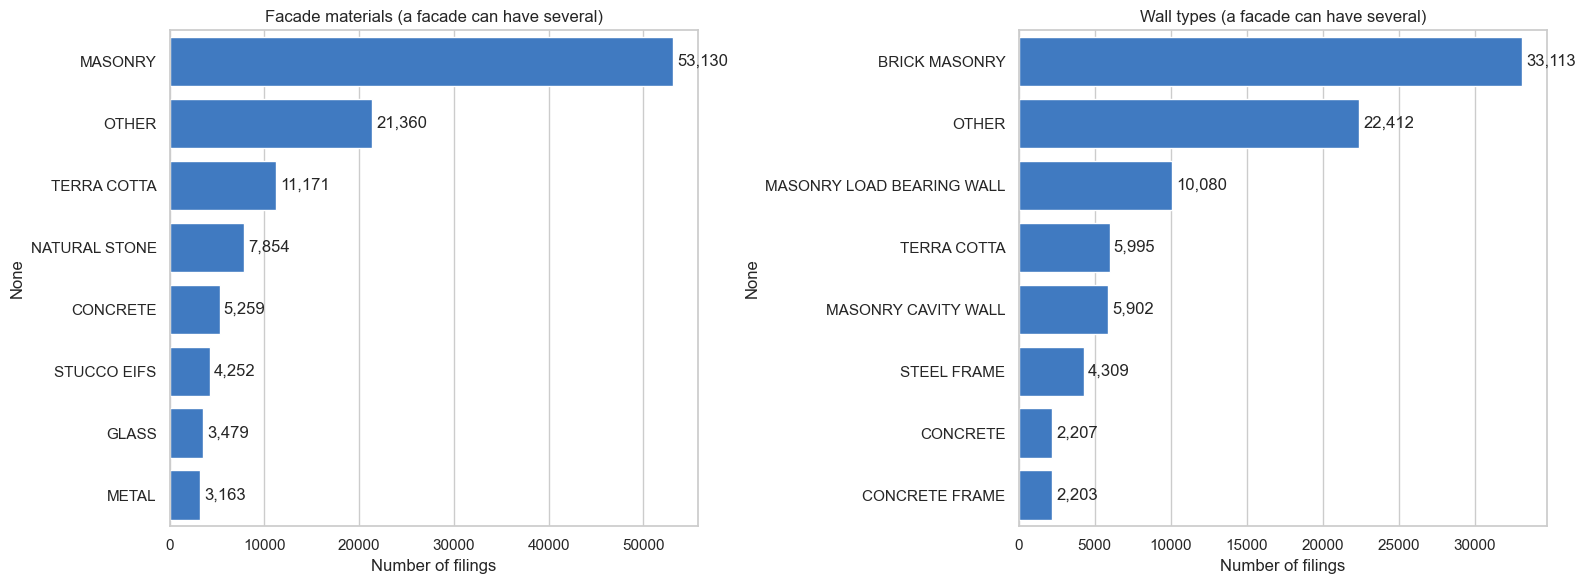

In [43]:
# Number of filings per material and per wall type
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

material_counts = df_clean[material_columns].sum().sort_values(ascending=False)
material_counts.index = material_counts.index.str.replace("MATERIAL_", "").str.replace("_", " ")
sns.barplot(x=material_counts.values, y=material_counts.index, color="#2a78d6", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", padding=3)
axes[0].set_title("Facade materials (a facade can have several)")
axes[0].set_xlabel("Number of filings")

wall_counts = df_clean[wall_columns].sum().sort_values(ascending=False)
wall_counts.index = wall_counts.index.str.replace("WALL_TYPE_", "").str.replace("_", " ")
sns.barplot(x=wall_counts.values, y=wall_counts.index, color="#2a78d6", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="{:,.0f}", padding=3)
axes[1].set_title("Wall types (a facade can have several)")
axes[1].set_xlabel("Number of filings")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_facade_types.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
# Filings per borough
df_clean["BOROUGH"].value_counts().to_frame("filings")

,filings
BOROUGH,
MANHATTAN,40640
BROOKLYN,9333
BRONX,8723
QUEENS,8364
STATEN ISLAND,599


Masonry is on almost 80% of the facades (53,130 filings), then "Other" (21,360). "Other" is vague, and the column that described it
was 74-96% empty (dropped in 1.4), so we can't say more about those facades.
Manhattan has 60% of all filings (40,640), Staten Island only 599, **so results for Staten Island are less sure.**

## 2.4 Correlation

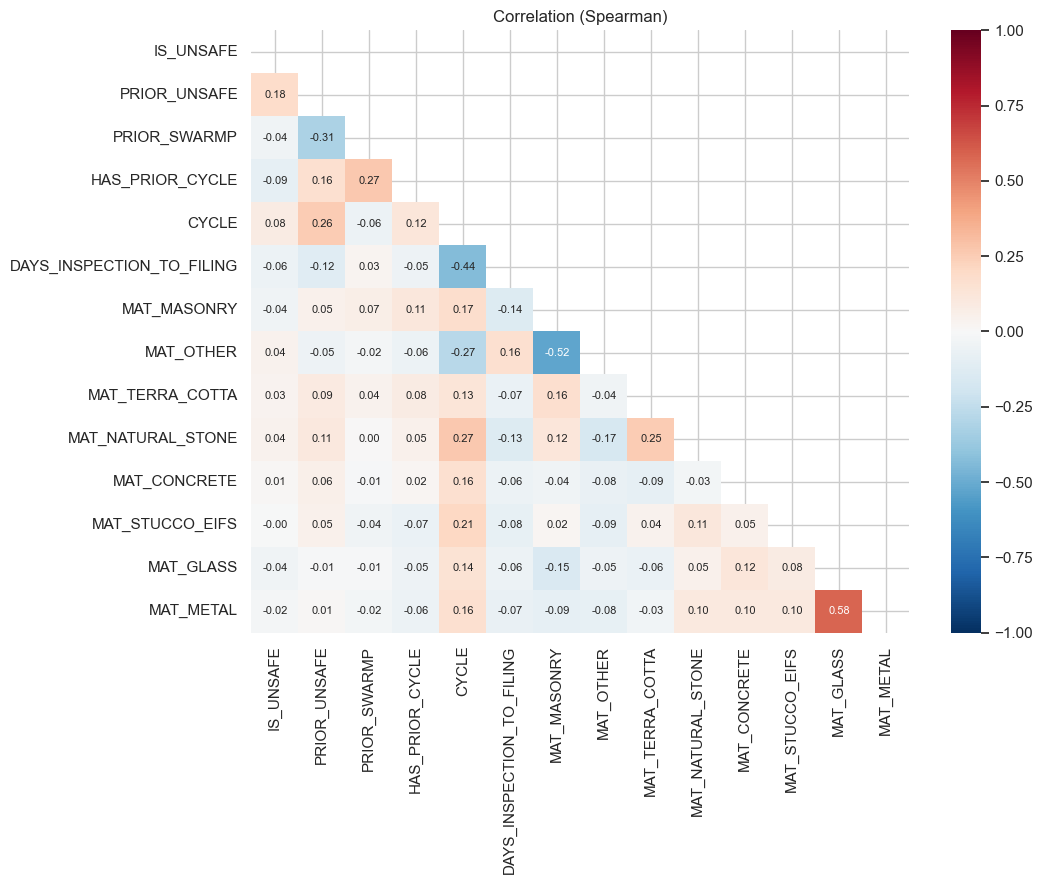

IS_UNSAFE                    1.00
PRIOR_UNSAFE                 0.18
CYCLE                        0.08
MAT_OTHER                    0.04
MAT_NATURAL_STONE            0.04
MAT_TERRA_COTTA              0.03
MAT_CONCRETE                 0.01
MAT_STUCCO_EIFS             -0.00
MAT_METAL                   -0.02
PRIOR_SWARMP                -0.04
MAT_MASONRY                 -0.04
MAT_GLASS                   -0.04
DAYS_INSPECTION_TO_FILING   -0.06
HAS_PRIOR_CYCLE             -0.09
Name: IS_UNSAFE, dtype: float64

In [45]:
# Prior status as 1/0 columns, so it can go in the correlation
df_corr = df_clean.copy()
df_corr["PRIOR_UNSAFE"] = (df_corr["PRIOR_STATUS"] == "UNSAFE").astype(int)
df_corr["PRIOR_SWARMP"] = (df_corr["PRIOR_STATUS"] == "SWARMP").astype(int)

corr_columns = ["IS_UNSAFE", "PRIOR_UNSAFE", "PRIOR_SWARMP", "HAS_PRIOR_CYCLE", "CYCLE", "DAYS_INSPECTION_TO_FILING",
                *material_columns]
corr = df_corr[corr_columns].astype(float).corr(method="spearman")
corr.index = corr.columns = [c.replace("MATERIAL_", "MAT_") for c in corr.columns]

# Hide upper half
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation (Spearman)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

corr["IS_UNSAFE"].sort_values(ascending=False)

<span style="color:#b2182b">**Red**</span> = go up together, <span style="color:#2166ac">**blue**</span> = one goes up the other goes down, **white** = no relation.

All the correlations with `IS_UNSAFE` are weak. The strongest one is `PRIOR_UNSAFE` (0.18): a facade that was UNSAFE last time is more likely to be UNSAFE again.
The materials alone are close to 0. Glass and metal go together (0.58), probably glass curtain walls with metal frames.
Newer cycles have shorter delays (-0.44), so owners file faster now.

Correlation only looks at one pair of columns at a time and is not causation. A model that combines several columns can still do better than any single one.
Penalties are not in here on purpose: they come after the result (leakage).

## 2.5 Q1: does the previous inspection predict the next one?

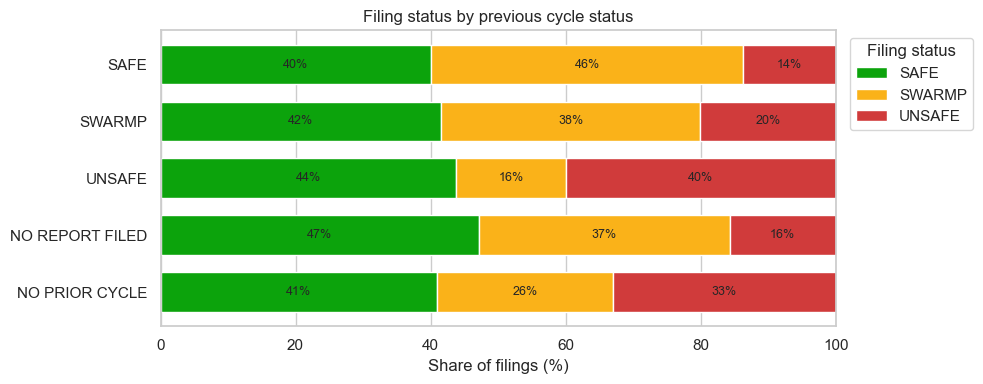

FILING_STATUS,SAFE,SWARMP,UNSAFE,filings
PRIOR_STATUS_FILLED,,,,
SAFE,40.10,46.20,13.70,23344
SWARMP,41.60,38.30,20.10,23612
UNSAFE,43.70,16.40,39.90,10444
NO REPORT FILED,47.20,37.10,15.70,2262
NO PRIOR CYCLE,40.90,26.10,32.90,7997


In [46]:
def status_share_plot(group_column, order, title, filename):
    """100% stacked bars: % of SAFE / SWARMP / UNSAFE in each group."""
    share = pd.crosstab(df_clean[group_column], df_clean["FILING_STATUS"], normalize="index") * 100
    share = share.reindex(order)[STATUS_ORDER]

    ax = share.plot(kind="barh", stacked=True, figsize=(10, 0.5 * len(share) + 1.5), width=0.7,
                    color=[STATUS_COLORS[s] for s in STATUS_ORDER], edgecolor="white")
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{w:.0f}%" if w >= 6 else "" for w in container.datavalues],
                     label_type="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("Share of filings (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.invert_yaxis()
    ax.legend(title="Filing status", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

    # Also return the numbers, with the number of filings per group
    share["filings"] = df_clean[group_column].value_counts()
    return share.round(1)


df_clean["PRIOR_STATUS_FILLED"] = df_clean["PRIOR_STATUS"].fillna("NO PRIOR CYCLE")
status_share_plot("PRIOR_STATUS_FILLED", ["SAFE", "SWARMP", "UNSAFE", "NO REPORT FILED", "NO PRIOR CYCLE"],
                  "Filing status by previous cycle status", "06_status_by_prior_status.png")

The previous result is the best signal we have. A facade that was **UNSAFE** last cycle is UNSAFE again **40%** of the time,
compared with **14%** for one that was SAFE. Facades also get worse over time: 46% of the SAFE ones become SWARMP.
But 44% of the UNSAFE ones are SAFE in the next cycle, so many owners do fix them.
Buildings with no previous cycle in the data are UNSAFE 33% of the time, more than the average.

## 2.6 Q2: are some facade materials and wall types more often unsafe?

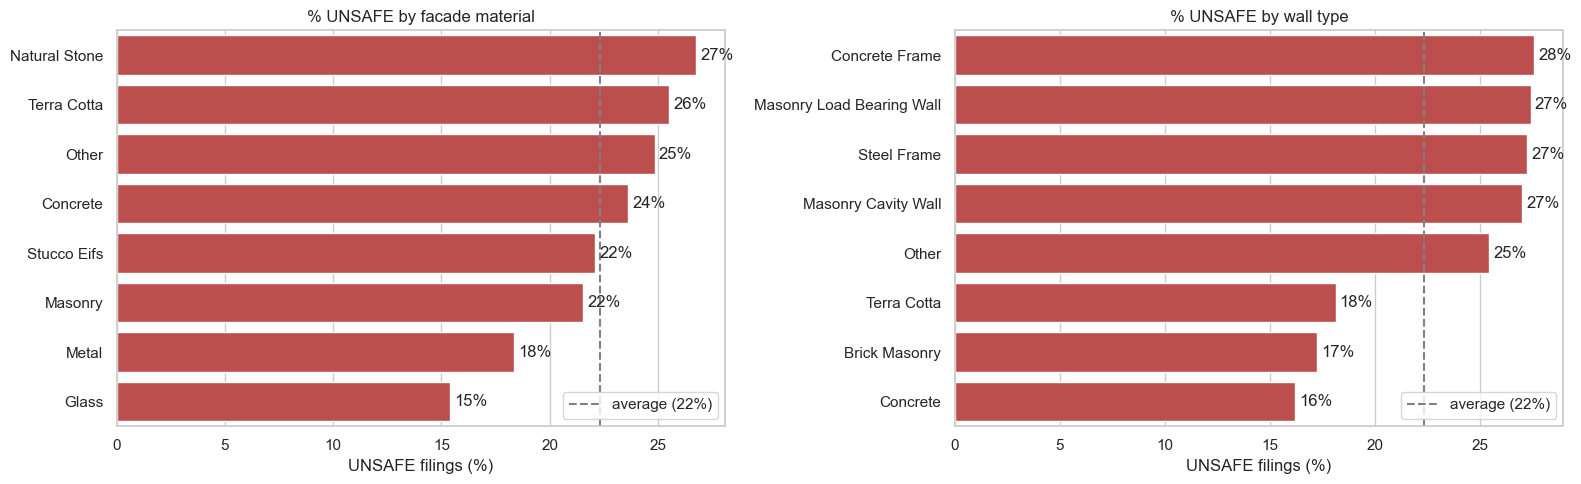

         name  filings  unsafe_pct
Natural Stone     7854       26.80
  Terra Cotta    11171       25.50
        Other    21360       24.90
     Concrete     5259       23.60
  Stucco Eifs     4252       22.10
      Masonry    53130       21.50
        Metal     3163       18.40
        Glass     3479       15.40

                     name  filings  unsafe_pct
           Concrete Frame     2203       27.60
Masonry Load Bearing Wall    10080       27.40
              Steel Frame     4309       27.20
      Masonry Cavity Wall     5902       27.00
                    Other    22412       25.50
              Terra Cotta     5995       18.10
            Brick Masonry    33113       17.30
                 Concrete     2207       16.20


In [47]:
def unsafe_rate(columns, prefix):
    """% UNSAFE among the filings that have each material / wall type."""
    rows = []
    for col in columns:
        has_it = df_clean[col] == 1
        rows.append({
            "name": col.replace(prefix, "").replace("_", " ").title(),
            "filings": int(has_it.sum()),
            "unsafe_pct": df_clean.loc[has_it, "IS_UNSAFE"].mean() * 100,
        })
    return pd.DataFrame(rows).sort_values("unsafe_pct", ascending=False)


material_rate = unsafe_rate(material_columns, "MATERIAL_")
wall_rate = unsafe_rate(wall_columns, "WALL_TYPE_")
average_unsafe = df_clean.loc[df_clean["EXTERIOR_WALL_MATERIALS"].notna(), "IS_UNSAFE"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, data, title in [(axes[0], material_rate, "Facade material"), (axes[1], wall_rate, "Wall type")]:
    sns.barplot(data=data, x="unsafe_pct", y="name", color=STATUS_COLORS["UNSAFE"], ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
    ax.axvline(average_unsafe, color="grey", linestyle="--", label=f"average ({average_unsafe:.0f}%)")
    ax.set_title(f"% UNSAFE by {title.lower()}")
    ax.set_xlabel("UNSAFE filings (%)")
    ax.set_ylabel("")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "07_unsafe_by_facade.png", dpi=150, bbox_inches="tight")
plt.show()

print(material_rate.round(1).to_string(index=False))
print()
print(wall_rate.round(1).to_string(index=False))

Natural stone (27%) and terra cotta (26%) are UNSAFE more often than the average (22%), glass (15%) and metal (18%) less often.
For wall types, frames and load-bearing / cavity masonry walls are around 27%, brick masonry 17%.
The differences are real but not huge (about 10 points between the top and the bottom).
A facade can have several materials, so the groups overlap: one filing can count in more than one bar.

## 2.7 Q3: does the borough matter?

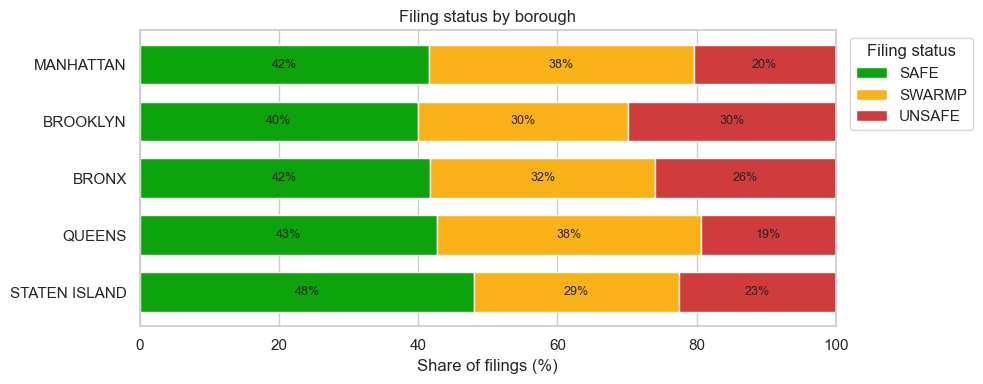

FILING_STATUS,SAFE,SWARMP,UNSAFE,filings
BOROUGH,,,,
MANHATTAN,41.50,38.10,20.40,40640
BROOKLYN,39.90,30.20,29.90,9333
BRONX,41.60,32.50,25.90,8723
QUEENS,42.70,37.90,19.40,8364
STATEN ISLAND,48.10,29.40,22.50,599


In [48]:
borough_order = df_clean["BOROUGH"].value_counts().index
status_share_plot("BOROUGH", borough_order, "Filing status by borough", "08_status_by_borough.png")

In [49]:
# Is it the borough, or the facades in that borough? Masonry share per borough
df_clean.groupby("BOROUGH")[["MATERIAL_MASONRY", "MATERIAL_TERRA_COTTA", "MATERIAL_NATURAL_STONE", "MATERIAL_GLASS"]] \
    .mean().mul(100).round(1).loc[borough_order]

,MATERIAL_MASONRY,MATERIAL_TERRA_COTTA,MATERIAL_NATURAL_STONE,MATERIAL_GLASS
BOROUGH,,,,
MANHATTAN,83.50,25.30,17.40,7.10
BROOKLYN,73.10,4.80,5.00,3.80
BRONX,78.20,7.70,3.60,1.20
QUEENS,82.20,1.10,2.60,3.00
STATEN ISLAND,61.10,1.40,1.30,0.00


Brooklyn (30% UNSAFE) and the Bronx (26%) are clearly above Manhattan (20%) and Queens (19%).
It's not because of the materials: Manhattan has by far the most terra cotta and natural stone (the "risky" materials from Q2),
and it's still lower. So something else that isn't in the data (building age, maintenance, owners' money...) probably makes the difference.
Staten Island has only 599 filings, so its numbers are less sure.

## 2.8 Q4: did the results change between cycles?

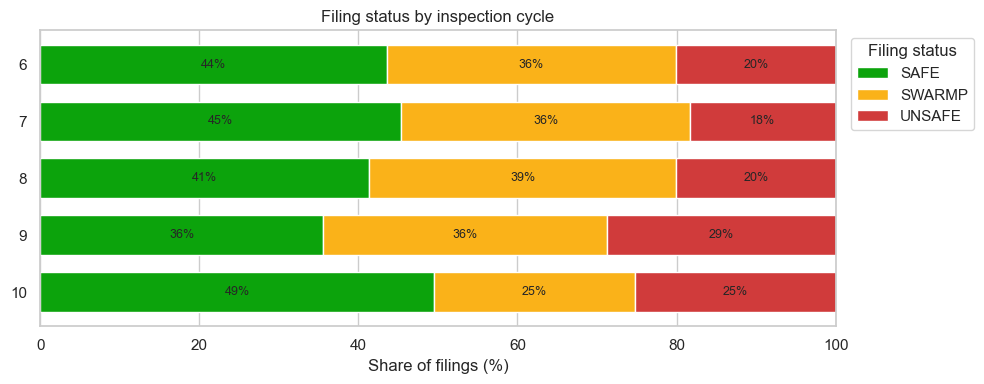

FILING_STATUS,SAFE,SWARMP,UNSAFE,filings
CYCLE,,,,
6,43.50,36.40,20.10,15290
7,45.40,36.30,18.30,14690
8,41.30,38.70,20.00,15627
9,35.60,35.60,28.70,18860
10,49.50,25.40,25.20,3191


In [50]:
status_share_plot("CYCLE", [6, 7, 8, 9, 10], "Filing status by inspection cycle", "09_status_by_cycle.png")

Cycles 6, 7 and 8 are very similar (18-20% UNSAFE). Cycle 9 jumps to **29%** UNSAFE.
Cycle 10 started in 2024 and only has 3,191 filings so far, so it can still change.
The data doesn't say why cycle 9 is higher (stricter inspections, older facades...), but it means `CYCLE` should be a model input,
and that a model trained on old cycles may underestimate UNSAFE in new ones.

# 3. Conclusions

### What we found
- The data needed a fair amount of cleaning: 19,799 filings were placeholders with no inspection (all the AUTO-GENERATED ones),
  the same values were written in different capitals, dates were text, and there were placeholder BINs, a fake block 99999 and typos.
  In the end we have 67,659 real inspection reports.
- About 1 in 5 reports (22%) is UNSAFE.
- The previous result matters the most: UNSAFE last cycle means 40% UNSAFE again, against 14% after a SAFE one.
- Materials make a smaller difference: natural stone and terra cotta are more often UNSAFE (26-27%), glass and metal less (15-18%).
- Brooklyn and the Bronx have more UNSAFE facades than Manhattan, even though Manhattan has more of the "risky" materials.
- Cycle 9 has clearly more UNSAFE results (29%) than the cycles before (18-20%).

### Limitations
- Only buildings taller than 6 stories, only NYC.
- The result is the inspector's judgement, so two inspectors could rate the same facade differently.
- No building age, height or size in the data, which probably matter a lot.
- "Other" is a big, vague material and wall type group.
- We removed the filings without a report, so everything here is about buildings whose owners did file.

### Ready for modelling
- The thing to predict is `FILING_STATUS` (3 classes) or `IS_UNSAFE` (yes/no). Only 22% are UNSAFE, so we need a stratified split and
  metrics like F1 or balanced accuracy, not just accuracy.
- Good inputs: `PRIOR_STATUS` (with `NO PRIOR CYCLE` as its own value), the `MATERIAL_` and `WALL_TYPE_` columns, `BOROUGH`, `CYCLE`.
- We can't use the penalty columns as inputs: the city gives them after the result (leakage).
- The same building shows up in several cycles, so train and test should be split **by building** (`BIN`),
  otherwise the model is tested on buildings it has already seen.